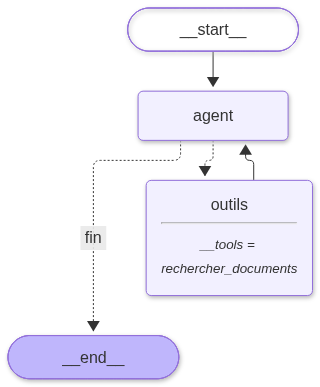

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from app.rag_agent import graph, creer_graphe
from langchain_core.messages import HumanMessage
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print(graph.get_graph().draw_mermaid())

In [2]:
def tracer(question, graphe=graph, config=None):
    print(f"👤 {question}\n")
    for etape in graphe.stream({"messages": [HumanMessage(question)]}, config=config, stream_mode="updates"):
        for noeud, mise_a_jour in etape.items():
            message = mise_a_jour["messages"][-1]
            if noeud == "agent" and message.tool_calls:
                for appel in message.tool_calls:
                    print(f"🧠 [agent]  décide d'appeler {appel['name']}({appel['args']})")
            elif noeud == "outils":
                print(f"👀 [outils] {len(message.content)} caractères de contexte récupérés")
            else:
                print(f"✅ [agent]  réponse finale :\n{message.content}")

tracer("Comment fonctionne l'attention multi-têtes ?")

👤 Comment fonctionne l'attention multi-têtes ?

🧠 [agent]  décide d'appeler rechercher_documents({'requete': 'how multi-head attention works in Transformer model'})
👀 [outils] 3844 caractères de contexte récupérés
✅ [agent]  réponse finale :
L'attention multi-têtes fonctionne en divisant l'attention en plusieurs "têtes" parallèles (h=8 dans le cas du Transformer), chacune capable d'attacher à des sous-espaces de représentation différents de l'entrée. Chaque tête utilise des matrices de projection spécifiques (W_Qi, W_Ki, W_Vi) pour traiter des aspects distincts de l'information, puis les résultats sont concaténés avant d'être projetés pour obtenir la sortie finale [attention_is_all_you_need.pdf, page 5]. Ce mécanisme permet au modèle de capturer des relations complexes entre les positions de l'entrée tout en réduisant le coût computationnel par rapport à l'attention mono-tête [attention_is_all_you_need.pdf, page 2]. Le Transformer utilise l'attention multi-têtes dans trois contextes : 

In [3]:
tracer("Bonjour !")
print("\n" + "=" * 70 + "\n")
tracer("Quel score BLEU le Transformer obtient-il en traduction anglais-allemand ?")
print("\n" + "=" * 70 + "\n")
tracer("Quel est le score MMLU de GPT-4 dans ce document ?")

👤 Bonjour !

✅ [agent]  réponse finale :
Bonjour ! 😊 Comment puis-je vous aider aujourd'hui ?


👤 Quel score BLEU le Transformer obtient-il en traduction anglais-allemand ?

🧠 [agent]  décide d'appeler rechercher_documents({'requete': 'BLEU score English-German translation Transformer'})
👀 [outils] 3938 caractères de contexte récupérés
✅ [agent]  réponse finale :
Le Transformer obtient un score BLEU de **28,4** sur la tâche de traduction anglais-allemand (WMT 2014) avec le modèle "big" [attention_is_all_you_need.pdf, page 1] et [attention_is_all_you_need.pdf, page 8]. Ce score est supérieur de plus de 2,0 BLEU par rapport aux modèles précédemment publiés (y compris les ensembles).


👤 Quel est le score MMLU de GPT-4 dans ce document ?

🧠 [agent]  décide d'appeler rechercher_documents({'requete': 'MMLU score GPT-4'})
👀 [outils] 3338 caractères de contexte récupérés
✅ [agent]  réponse finale :
Le document fourni (l'article "Attention Is All You Need" sur le Transformer) ne contient aucun

In [4]:
from langgraph.checkpoint.memory import InMemorySaver

graphe_memoire = creer_graphe(checkpointer=InMemorySaver())
config = {"configurable": {"thread_id": "rag-1"}}

tracer("Qu'est-ce que l'encodage positionnel ?", graphe_memoire, config)
print("\n" + "=" * 70 + "\n")
tracer("Pourquoi les auteurs ont-ils choisi des sinusoïdes pour ça ?", graphe_memoire, config)

👤 Qu'est-ce que l'encodage positionnel ?

🧠 [agent]  décide d'appeler rechercher_documents({'requete': 'positional encoding in Transformer model'})
👀 [outils] 3982 caractères de contexte récupérés
✅ [agent]  réponse finale :
L'encodage positionnel est une technique utilisée dans les modèles Transformer pour injecter des informations sur la position des tokens dans une séquence. Contrairement aux réseaux de neurones récurrents ou aux réseaux convolutifs, les Transformers n'ont pas de mécanisme intrinsèque pour gérer l'ordre des éléments, ce qui justifie l'utilisation de cet encodage [attention_is_all_you_need.pdf, page 6]. 

Dans ce modèle, les encodages positionnels sont calculés à l'aide de fonctions sinus et cosinus de fréquences différentes, définies par les formules suivantes :  
$$ PE(pos, 2i) = \sin\left(\frac{pos}{10000^{2i/d_{\text{model}}}}\right) $$  
$$ PE(pos, 2i+1) = \cos\left(\frac{pos}{10000^{2i/d_{\text{model}}}}\right) $$  
où $ pos $ est la position du token et $ i $ 